In [1]:
import sys

print("Python Version:", sys.version)
print("Project Setup Started Successfully!")

Python Version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Project Setup Started Successfully!


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn streamlit joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import streamlit as st
import joblib

print("All Libraries Imported Successfully!")
print("Pandas Version:", pd.__version__)
print("Scikit-learn Version:", sklearn.__version__)

All Libraries Imported Successfully!
Pandas Version: 3.1.1
Scikit-learn Version: 1.9.1


In [4]:
import pandas as pd

data = {
    "Date": [
        "2025-01-01", "2025-01-05", "2025-01-10",
        "2025-02-01", "2025-02-05", "2025-02-10",
        "2025-03-01", "2025-03-05", "2025-03-10",
        "2025-04-01", "2025-04-05", "2025-04-10"
    ],
    "Product": [
        "Laptop", "Mobile", "Headphones",
        "Laptop", "Mobile", "Headphones",
        "Laptop", "Mobile", "Headphones",
        "Laptop", "Mobile", "Headphones"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories"
    ],
    "Quantity": [2, 5, 10, 3, 6, 12, 4, 7, 15, 5, 8, 18],
    "Price": [50000, 20000, 1000, 50000, 20000, 1000,
              50000, 20000, 1000, 50000, 20000, 1000]
}

df = pd.DataFrame(data)

df["Sales"] = df["Quantity"] * df["Price"]

df.to_csv("sales_data.csv", index=False)

print("Dataset Created Successfully!")
df.head()

Dataset Created Successfully!


,Date,Product,Category,Quantity,Price,Sales
0,2025-01-01,Laptop,Electronics,2,50000,100000
1,2025-01-05,Mobile,Electronics,5,20000,100000
2,2025-01-10,Headphones,Accessories,10,1000,10000
3,2025-02-01,Laptop,Electronics,3,50000,150000
4,2025-02-05,Mobile,Electronics,6,20000,120000


In [5]:
# Display first 5 rows
display(df.head())

# Check dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

,Date,Product,Category,Quantity,Price,Sales
0,2025-01-01,Laptop,Electronics,2,50000,100000
1,2025-01-05,Mobile,Electronics,5,20000,100000
2,2025-01-10,Headphones,Accessories,10,1000,10000
3,2025-02-01,Laptop,Electronics,3,50000,150000
4,2025-02-05,Mobile,Electronics,6,20000,120000


Dataset Shape: (12, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      12 non-null     str  
 1   Product   12 non-null     str  
 2   Category  12 non-null     str  
 3   Quantity  12 non-null     int64
 4   Price     12 non-null     int64
 5   Sales     12 non-null     int64
dtypes: int64(3), str(3)
memory usage: 1.0 KB

Statistical Summary:


,Quantity,Price,Sales
count,12.000000,12.000000,12.00000
mean,7.916667,23666.666667,106250.00000
std,4.944388,21068.431073,79729.22927
min,2.000000,1000.000000,10000.00000
25%,4.750000,1000.000000,17250.00000
50%,6.500000,20000.000000,110000.00000
75%,10.500000,50000.000000,152500.00000
max,18.000000,50000.000000,250000.00000


In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Handle missing values
df = df.dropna()

print("\nAfter Data Cleaning:")
print("Dataset Shape:", df.shape)

print("Data Cleaning Completed Successfully!")

Missing Values:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Sales       0
dtype: int64

Duplicate Records:
0

After Data Cleaning:
Dataset Shape: (12, 6)
Data Cleaning Completed Successfully!


In [7]:
# Total Sales
total_sales = df["Sales"].sum()

# Average Sales
average_sales = df["Sales"].mean()

# Total Quantity Sold
total_quantity = df["Quantity"].sum()

# Product-wise Sales
product_sales = df.groupby("Product")["Sales"].sum()

print("SALES ANALYSIS REPORT")
print("----------------------")

print("Total Sales: Rs.", total_sales)
print("Average Sales: Rs.", round(average_sales, 2))
print("Total Quantity Sold:", total_quantity)

print("\nProduct-wise Sales:")
display(product_sales)

SALES ANALYSIS REPORT
----------------------
Total Sales: Rs. 1275000
Average Sales: Rs. 106250.0
Total Quantity Sold: 95

Product-wise Sales:


Product
Headphones     55000
Laptop        700000
Mobile        520000
Name: Sales, dtype: int64

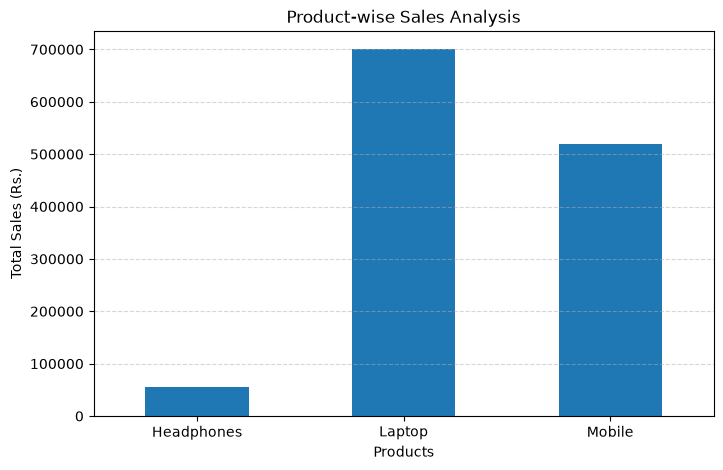

In [8]:
import matplotlib.pyplot as plt

# Product-wise Sales
product_sales = df.groupby("Product")["Sales"].sum()

# Create Bar Chart
plt.figure(figsize=(8, 5))

product_sales.plot(kind="bar")

plt.title("Product-wise Sales Analysis")
plt.xlabel("Products")
plt.ylabel("Total Sales (Rs.)")

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

Monthly Sales Report:


Month
April       428000
February    282000
January     210000
March       355000
Name: Sales, dtype: int64

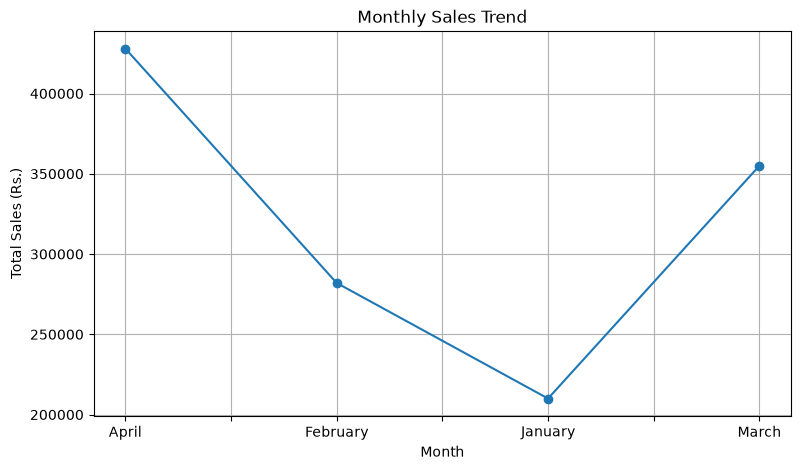

In [9]:
# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extract Month
df["Month"] = df["Date"].dt.month_name()

# Calculate Monthly Sales
monthly_sales = df.groupby("Month")["Sales"].sum()

print("Monthly Sales Report:")
display(monthly_sales)

# Create Line Chart
plt.figure(figsize=(9, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (Rs.)")

plt.grid(True)
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

# Convert Date into numerical format
df["Day"] = df["Date"].dt.day
df["Month_Number"] = df["Date"].dt.month

# Select input features
X = df[["Quantity", "Price", "Day", "Month_Number"]]

# Select target variable
y = df["Sales"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Machine Learning Data Prepared Successfully!")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Machine Learning Data Prepared Successfully!
Training Data: (9, 4)
Testing Data: (3, 4)


In [11]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression Model
model = LinearRegression()

# Train the Model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [12]:
# Predict Sales
y_pred = model.predict(X_test)

# Compare Actual vs Predicted Sales
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred.round(2)
})

print("Sales Prediction Results:")
display(comparison)

Sales Prediction Results:


,Actual Sales,Predicted Sales
0,160000,170045.6
1,250000,212534.2
2,100000,137465.8


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION REPORT")
print("------------------------")

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION REPORT
------------------------
Mean Absolute Error (MAE): 28325.73
Mean Squared Error (MSE): 969428726.03
Root Mean Squared Error (RMSE): 31135.65
R2 Score: 0.7449


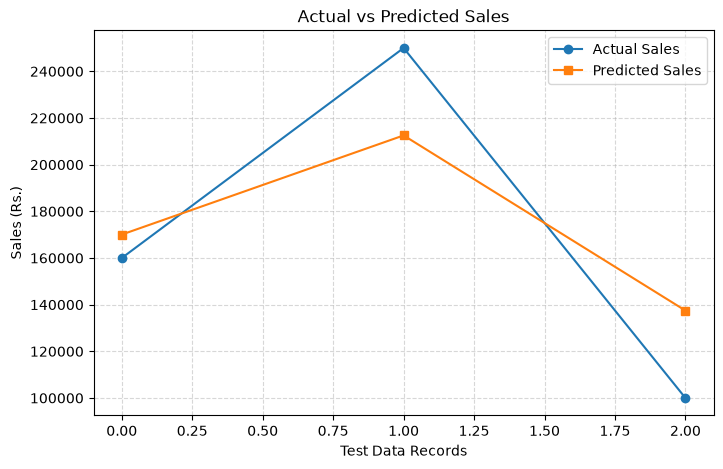

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual Sales"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="s",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Data Records")
plt.ylabel("Sales (Rs.)")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

In [15]:
import joblib

# Save trained model
joblib.dump(model, "sales_model.pkl")

print("Machine Learning Model Saved Successfully!")

Machine Learning Model Saved Successfully!


In [16]:
# Take input from user
quantity = int(input("Enter Quantity: "))
price = float(input("Enter Product Price: "))
day = int(input("Enter Day (1-31): "))
month = int(input("Enter Month (1-12): "))

# Prepare input data
new_data = pd.DataFrame({
    "Quantity": [quantity],
    "Price": [price],
    "Day": [day],
    "Month_Number": [month]
})

# Predict Sales
predicted_sales = model.predict(new_data)

print("\nPredicted Sales: Rs.", round(predicted_sales[0], 2))


Predicted Sales: Rs. 152638.52


In [17]:

import pandas as pd
import numpy as np

# Reproducible random data
np.random.seed(42)

# Number of records
n = 1000

# Generate sales dataset
dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31",
    periods=n
)

products = ["Laptop", "Mobile", "Headphones", "Tablet", "Keyboard", "Mouse"]

categories = {
    "Laptop": "Electronics",
    "Mobile": "Electronics",
    "Headphones": "Accessories",
    "Tablet": "Electronics",
    "Keyboard": "Accessories",
    "Mouse": "Accessories"
}

prices = {
    "Laptop": 55000,
    "Mobile": 25000,
    "Headphones": 2000,
    "Tablet": 18000,
    "Keyboard": 1200,
    "Mouse": 700
}

regions = ["North", "South", "East", "West", "Central"]

# Generate random values
product_list = np.random.choice(products, n)
quantity = np.random.randint(1, 11, n)
discount = np.random.choice([0, 5, 10, 15, 20], n)
region = np.random.choice(regions, n)

# Create DataFrame
df = pd.DataFrame({
    "Date": dates,
    "Product": product_list,
    "Category": [categories[p] for p in product_list],
    "Quantity": quantity,
    "Price": [prices[p] for p in product_list],
    "Discount": discount,
    "Region": region
})

# Calculate final sales after discount
df["Sales"] = (
    df["Quantity"] * df["Price"] *
    (1 - df["Discount"] / 100)
)

# Save new dataset
df.to_csv("sales_data.csv", index=False)

print("New dataset created successfully!")
print("Total Records:", len(df))

df.head()


New dataset created successfully!
Total Records: 1000


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01 00:00:00.000000,Tablet,Electronics,6,18000,15,North,91800.0
1,2025-01-01 08:44:41.081081,Keyboard,Accessories,5,1200,0,West,6000.0
2,2025-01-01 17:29:22.162162,Headphones,Accessories,6,2000,0,East,12000.0
3,2025-01-02 02:14:03.243243,Keyboard,Accessories,6,1200,10,North,6480.0
4,2025-01-02 10:58:44.324324,Keyboard,Accessories,7,1200,20,South,6720.0


In [18]:

# Load the new dataset
df = pd.read_csv("sales_data.csv")

# Display first 5 records
print("First 5 Records:")
display(df.head())

# Check total rows and columns
print("\nDataset Shape:")
print(df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())


First 5 Records:


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01 00:00:00.000000,Tablet,Electronics,6,18000,15,North,91800.0
1,2025-01-01 08:44:41.081081,Keyboard,Accessories,5,1200,0,West,6000.0
2,2025-01-01 17:29:22.162162,Headphones,Accessories,6,2000,0,East,12000.0
3,2025-01-02 02:14:03.243243,Keyboard,Accessories,6,1200,10,North,6480.0
4,2025-01-02 10:58:44.324324,Keyboard,Accessories,7,1200,20,South,6720.0



Dataset Shape:
(1000, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      1000 non-null   str    
 1   Product   1000 non-null   str    
 2   Category  1000 non-null   str    
 3   Quantity  1000 non-null   int64  
 4   Price     1000 non-null   int64  
 5   Discount  1000 non-null   int64  
 6   Region    1000 non-null   str    
 7   Sales     1000 non-null   float64
dtypes: float64(1), int64(3), str(4)
memory usage: 110.3 KB

Missing Values:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Discount    0
Region      0
Sales       0
dtype: int64

Statistical Summary:


,Quantity,Price,Discount,Sales
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,5.447000,17809.900000,10.245000,85772.015000
std,2.887131,19762.050264,7.107425,115954.563468
min,1.000000,700.000000,0.000000,560.000000
25%,3.000000,1200.000000,5.000000,5400.000000
50%,5.000000,18000.000000,10.000000,20000.000000
75%,8.000000,25000.000000,15.000000,135000.000000
max,10.000000,55000.000000,20.000000,550000.000000


In [19]:

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Remove rows containing missing values
df = df.dropna()

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Remove invalid records
df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (df["Discount"] >= 0) &
    (df["Discount"] <= 100)
]

# Recalculate Sales
df["Sales"] = (
    df["Quantity"] * df["Price"] *
    (1 - df["Discount"] / 100)
)

# Reset index
df = df.reset_index(drop=True)

# Save cleaned dataset
df.to_csv("sales_data.csv", index=False)

print("\nData Preprocessing Completed!")
print("Final Dataset Shape:", df.shape)

display(df.head())


Duplicate Records: 0

Missing Values:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Discount    0
Region      0
Sales       0
dtype: int64

Data Preprocessing Completed!
Final Dataset Shape: (1000, 8)


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01 00:00:00.000000,Tablet,Electronics,6,18000,15,North,91800.0
1,2025-01-01 08:44:41.081081,Keyboard,Accessories,5,1200,0,West,6000.0
2,2025-01-01 17:29:22.162162,Headphones,Accessories,6,2000,0,East,12000.0
3,2025-01-02 02:14:03.243243,Keyboard,Accessories,6,1200,10,North,6480.0
4,2025-01-02 10:58:44.324324,Keyboard,Accessories,7,1200,20,South,6720.0


In [20]:

from sklearn.model_selection import train_test_split

# Extract date features
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

# Select input features
X = df[
    ["Quantity", "Price", "Discount",
     "Month", "Day", "Product", "Region"]
]

# Convert categorical columns into numerical values
X = pd.get_dummies(
    X,
    columns=["Product", "Region"],
    dtype=int
)

# Select target variable
y = df["Sales"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Feature Selection Completed!")
print("Total Features:", X.shape[1])
print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

display(X.head())


Feature Selection Completed!
Total Features: 16
Training Records: 800
Testing Records: 200


,Quantity,Price,Discount,Month,Day,Product_Headphones,Product_Keyboard,Product_Laptop,Product_Mobile,Product_Mouse,Product_Tablet,Region_Central,Region_East,Region_North,Region_South,Region_West
0,6,18000,15,1,1,0,0,0,0,0,1,0,0,1,0,0
1,5,1200,0,1,1,0,1,0,0,0,0,0,0,0,0,1
2,6,2000,0,1,1,1,0,0,0,0,0,0,1,0,0,0
3,6,1200,10,1,2,0,1,0,0,0,0,0,0,1,0,0
4,7,1200,20,1,2,0,1,0,0,0,0,0,0,0,1,0


In [21]:

from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)

print("Machine Learning Model Trained Successfully!")

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nFirst 5 Predictions:")
print(y_pred[:5])


Machine Learning Model Trained Successfully!
Training Records: 800
Testing Records: 200

First 5 Predictions:
[157160.62587603 199215.74792639 180580.13449793  97312.14816038
 168954.45040361]


In [22]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")

print("Mean Absolute Error (MAE):", round(mae, 2))

print("Mean Squared Error (MSE):", round(mse, 2))

print("Root Mean Squared Error (RMSE):", round(rmse, 2))

print("R2 Score:", round(r2, 4))


MODEL EVALUATION RESULTS
Mean Absolute Error (MAE): 36512.71
Mean Squared Error (MSE): 2445590997.65
Root Mean Squared Error (RMSE): 49452.92
R2 Score: 0.8107


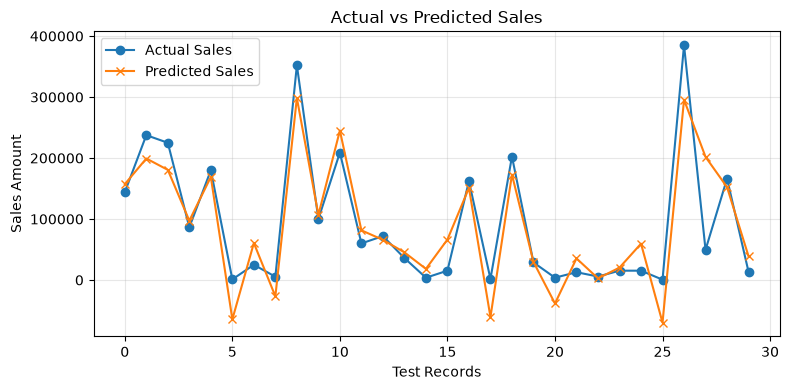

In [23]:

import matplotlib.pyplot as plt

# Compare actual and predicted sales
plt.figure(figsize=(8, 4))

plt.plot(
    y_test.values[:30],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    y_pred[:30],
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Records")
plt.ylabel("Sales Amount")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:

import joblib

# Save trained ML model
joblib.dump(model, "sales_model.pkl")

# Save feature columns
joblib.dump(X.columns.tolist(), "sales_features.pkl")

print("Model saved successfully!")
print("Feature columns saved successfully!")


Model saved successfully!
Feature columns saved successfully!


In [25]:
import os

print("Model File Exists:", os.path.exists("sales_model.pkl"))
print("Features File Exists:", os.path.exists("sales_features.pkl"))

Model File Exists: True
Features File Exists: True


In [26]:

import pandas as pd
import numpy as np

# Reproducible dataset
np.random.seed(42)

# Total records
n = 1000

# 40 products with categories
products = {
    "Laptop": ("Electronics", 55000),
    "Mobile": ("Electronics", 25000),
    "Headphones": ("Electronics", 2000),
    "Tablet": ("Electronics", 18000),
    "Keyboard": ("Electronics", 1200),
    "Mouse": ("Electronics", 700),
    "Monitor": ("Electronics", 12000),
    "Printer": ("Electronics", 9000),

    "T-Shirt": ("Clothing", 600),
    "Shirt": ("Clothing", 1000),
    "Jeans": ("Clothing", 1800),
    "Jacket": ("Clothing", 3000),
    "Dress": ("Clothing", 2200),
    "Hoodie": ("Clothing", 1500),

    "Sneakers": ("Footwear", 2500),
    "Formal Shoes": ("Footwear", 3000),
    "Sandals": ("Footwear", 800),
    "Sports Shoes": ("Footwear", 2800),

    "Mixer": ("Home & Kitchen", 3500),
    "Microwave": ("Home & Kitchen", 12000),
    "Electric Kettle": ("Home & Kitchen", 1500),
    "Cookware Set": ("Home & Kitchen", 2500),
    "Office Chair": ("Home & Kitchen", 6500),
    "Table Lamp": ("Home & Kitchen", 1200),

    "Rice": ("Groceries", 1200),
    "Cooking Oil": ("Groceries", 180),
    "Tea": ("Groceries", 350),
    "Coffee": ("Groceries", 450),
    "Biscuits": ("Groceries", 50),

    "Shampoo": ("Beauty & Personal Care", 300),
    "Face Wash": ("Beauty & Personal Care", 250),
    "Moisturizer": ("Beauty & Personal Care", 500),
    "Perfume": ("Beauty & Personal Care", 1500),

    "Yoga Mat": ("Sports & Fitness", 800),
    "Dumbbells": ("Sports & Fitness", 1800),
    "Football": ("Sports & Fitness", 700),

    "Notebook": ("Stationery", 80),
    "Pen Set": ("Stationery", 150),

    "Board Game": ("Toys & Games", 900),

    "Car Charger": ("Automotive", 600)
}

# Regions
regions = [
    "North",
    "South",
    "East",
    "West",
    "Central"
]

# Random product selection
product_list = np.random.choice(
    list(products.keys()),
    n
)

# Generate dates
date_range = pd.date_range(
    start="2025-01-01",
    end="2025-12-31"
)

dates = np.random.choice(
    date_range,
    n
)

# Generate quantity, discount and region
quantity = np.random.randint(1, 11, n)

discount = np.random.choice(
    [0, 5, 10, 15, 20],
    n
)

region = np.random.choice(
    regions,
    n
)

# Create dataset
df = pd.DataFrame({
    "Date": dates,
    "Product": product_list,
    "Category": [
        products[p][0] for p in product_list
    ],
    "Quantity": quantity,
    "Price": [
        products[p][1] for p in product_list
    ],
    "Discount": discount,
    "Region": region
})

# Calculate sales
df["Sales"] = (
    df["Quantity"] *
    df["Price"] *
    (1 - df["Discount"] / 100)
)

# Sort records by date
df = df.sort_values(
    "Date"
).reset_index(drop=True)

# Save dataset
df.to_csv(
    "sales_data.csv",
    index=False
)

print("New Dataset Created Successfully!")
print("Total Records:", len(df))
print("Total Products:", df["Product"].nunique())
print("Total Categories:", df["Category"].nunique())

print("\nAvailable Categories:")
print(df["Category"].unique())

print("\nFirst 5 Records:")
display(df.head())


New Dataset Created Successfully!
Total Records: 1000
Total Products: 40
Total Categories: 10

Available Categories:
<ArrowStringArray>
[           'Electronics',             'Stationery',         'Home & Kitchen',
       'Sports & Fitness', 'Beauty & Personal Care',              'Groceries',
               'Clothing',               'Footwear',           'Toys & Games',
             'Automotive']
Length: 10, dtype: str

First 5 Records:


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01,Headphones,Electronics,5,2000,0,North,10000.0
1,2025-01-01,Pen Set,Stationery,1,150,0,North,150.0
2,2025-01-01,Office Chair,Home & Kitchen,9,6500,15,Central,49725.0
3,2025-01-01,Football,Sports & Fitness,10,700,0,North,7000.0
4,2025-01-02,Cookware Set,Home & Kitchen,3,2500,15,North,6375.0


In [27]:

import pandas as pd

# Load the new dataset
df = pd.read_csv("sales_data.csv")

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# 1. Dataset size
print("DATASET SHAPE:")
print(df.shape)

# 2. Total records
print("\nTOTAL RECORDS:")
print(len(df))

# 3. Unique products
print("\nTOTAL PRODUCTS:")
print(df["Product"].nunique())

# 4. Categories
print("\nTOTAL CATEGORIES:")
print(df["Category"].nunique())

# 5. Products in each category
print("\nCATEGORY-WISE PRODUCT COUNT:")
print(df.groupby("Category")["Product"].nunique())

# 6. Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# 7. Duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

# 8. First five records
print("\nFIRST 5 RECORDS:")
display(df.head())

# 9. Statistical summary
print("\nSTATISTICAL SUMMARY:")
display(df.describe())


DATASET SHAPE:
(1000, 8)

TOTAL RECORDS:
1000

TOTAL PRODUCTS:
40

TOTAL CATEGORIES:
10

CATEGORY-WISE PRODUCT COUNT:
Category
Automotive                1
Beauty & Personal Care    4
Clothing                  6
Electronics               8
Footwear                  4
Groceries                 5
Home & Kitchen            6
Sports & Fitness          3
Stationery                2
Toys & Games              1
Name: Product, dtype: int64

MISSING VALUES:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Discount    0
Region      0
Sales       0
dtype: int64

DUPLICATE RECORDS:
0

FIRST 5 RECORDS:


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01,Headphones,Electronics,5,2000,0,North,10000.0
1,2025-01-01,Pen Set,Stationery,1,150,0,North,150.0
2,2025-01-01,Office Chair,Home & Kitchen,9,6500,15,Central,49725.0
3,2025-01-01,Football,Sports & Fitness,10,700,0,North,7000.0
4,2025-01-02,Cookware Set,Home & Kitchen,3,2500,15,North,6375.0



STATISTICAL SUMMARY:


,Date,Quantity,Price,Discount,Sales
count,1000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-04 14:47:02.400000,5.496000,4459.070000,10.020000,20355.997000
min,2025-01-01 00:00:00,1.000000,50.000000,0.000000,45.000000
25%,2025-04-01 12:00:00,3.000000,600.000000,5.000000,1998.750000
50%,2025-07-06 12:00:00,5.000000,1200.000000,10.000000,5440.000000
75%,2025-10-12 00:00:00,8.000000,2800.000000,15.000000,14400.000000
max,2025-12-31 00:00:00,10.000000,55000.000000,20.000000,522500.000000
std,NaN,2.804255,9862.264704,7.134459,49514.874946


In [28]:

# 1. Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# 2. Remove duplicates
df = df.drop_duplicates()

# 3. Handle missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

df = df.dropna()

# 4. Correct data types
df["Date"] = pd.to_datetime(df["Date"])

df["Quantity"] = pd.to_numeric(df["Quantity"])
df["Price"] = pd.to_numeric(df["Price"])
df["Discount"] = pd.to_numeric(df["Discount"])

# 5. Remove invalid records
df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (df["Discount"] >= 0) &
    (df["Discount"] <= 100)
]

# 6. Recalculate Sales
df["Sales"] = (
    df["Quantity"] *
    df["Price"] *
    (1 - df["Discount"] / 100)
)

# 7. Reset index
df = df.reset_index(drop=True)

# 8. Save cleaned dataset
df.to_csv("sales_data.csv", index=False)

print("\nData Preprocessing Completed!")
print("Final Dataset Shape:", df.shape)

display(df.head())


Duplicate Records: 0

Missing Values Before Cleaning:
Date        0
Product     0
Category    0
Quantity    0
Price       0
Discount    0
Region      0
Sales       0
dtype: int64

Data Preprocessing Completed!
Final Dataset Shape: (1000, 8)


,Date,Product,Category,Quantity,Price,Discount,Region,Sales
0,2025-01-01,Headphones,Electronics,5,2000,0,North,10000.0
1,2025-01-01,Pen Set,Stationery,1,150,0,North,150.0
2,2025-01-01,Office Chair,Home & Kitchen,9,6500,15,Central,49725.0
3,2025-01-01,Football,Sports & Fitness,10,700,0,North,7000.0
4,2025-01-02,Cookware Set,Home & Kitchen,3,2500,15,North,6375.0


In [29]:

from sklearn.model_selection import train_test_split

# Extract date features
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

# Select input features
X = df[
    [
        "Quantity",
        "Price",
        "Discount",
        "Month",
        "Day",
        "Product",
        "Region"
    ]
]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["Product", "Region"],
    dtype=int
)

# Select target variable
y = df["Sales"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Feature Selection Completed!")

print("\nTotal Features:", X.shape[1])
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nFeature Names:")
print(X.columns.tolist())

display(X.head())


Feature Selection Completed!

Total Features: 50
Training Records: 800
Testing Records: 200

Feature Names:
['Quantity', 'Price', 'Discount', 'Month', 'Day', 'Product_Biscuits', 'Product_Board Game', 'Product_Car Charger', 'Product_Coffee', 'Product_Cooking Oil', 'Product_Cookware Set', 'Product_Dress', 'Product_Dumbbells', 'Product_Electric Kettle', 'Product_Face Wash', 'Product_Football', 'Product_Formal Shoes', 'Product_Headphones', 'Product_Hoodie', 'Product_Jacket', 'Product_Jeans', 'Product_Keyboard', 'Product_Laptop', 'Product_Microwave', 'Product_Mixer', 'Product_Mobile', 'Product_Moisturizer', 'Product_Monitor', 'Product_Mouse', 'Product_Notebook', 'Product_Office Chair', 'Product_Pen Set', 'Product_Perfume', 'Product_Printer', 'Product_Rice', 'Product_Sandals', 'Product_Shampoo', 'Product_Shirt', 'Product_Sneakers', 'Product_Sports Shoes', 'Product_T-Shirt', 'Product_Table Lamp', 'Product_Tablet', 'Product_Tea', 'Product_Yoga Mat', 'Region_Central', 'Region_East', 'Region_Nor

,Quantity,Price,Discount,Month,Day,Product_Biscuits,Product_Board Game,Product_Car Charger,Product_Coffee,Product_Cooking Oil,...,Product_T-Shirt,Product_Table Lamp,Product_Tablet,Product_Tea,Product_Yoga Mat,Region_Central,Region_East,Region_North,Region_South,Region_West
0,5,2000,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,1,150,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,9,6500,15,1,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,10,700,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,3,2500,15,1,2,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [30]:

from sklearn.linear_model import LinearRegression

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

print("Training Score:", model.score(X_train, y_train))
print("Testing Score:", model.score(X_test, y_test))


Model Training Completed Successfully!
Training Score: 0.7478658507788487
Testing Score: 0.6936032623599516


In [31]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Predict sales on testing data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("R2 Score (%):", r2 * 100)


MODEL EVALUATION RESULTS
------------------------
MAE: 13167.12968457858
MSE: 839012538.4589993
RMSE: 28965.71315295032
R2 Score: 0.6936032623599516
R2 Score (%): 69.36032623599516


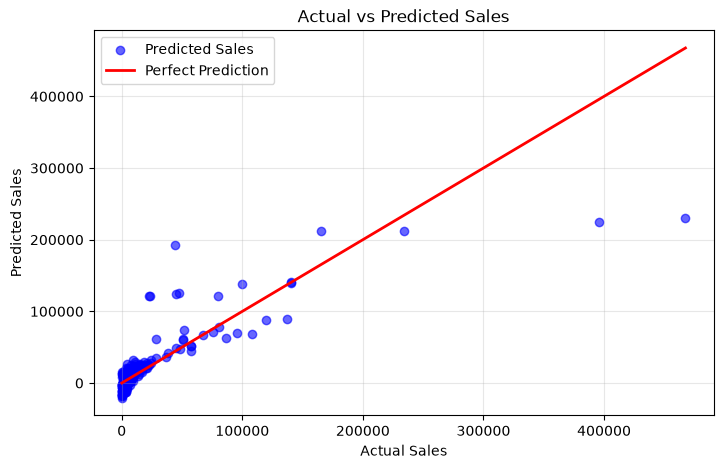

In [32]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6,
    color="blue",
    label="Predicted Sales"
)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [33]:

import joblib

# Save trained ML model
joblib.dump(model, "sales_model.pkl")

# Save feature column names
joblib.dump(X.columns.tolist(), "sales_features.pkl")

print("Model Saved Successfully!")
print("Saved Files:")
print("1. sales_model.pkl")
print("2. sales_features.pkl")


Model Saved Successfully!
Saved Files:
1. sales_model.pkl
2. sales_features.pkl


In [34]:

# Create sample new sales data
new_data = pd.DataFrame({
    "Quantity": [5],
    "Price": [25000],
    "Discount": [10],
    "Month": [11],
    "Day": [17],
    "Product": ["Mobile"],
    "Region": ["North"]
})

# Convert categorical columns into numerical columns
new_data = pd.get_dummies(
    new_data,
    columns=["Product", "Region"],
    dtype=int
)

# Match training feature columns
new_data = new_data.reindex(
    columns=X.columns,
    fill_value=0
)

# Predict sales
predicted_sales = model.predict(new_data)

print("NEW SALES PREDICTION")
print("--------------------")
print("Product: Mobile")
print("Quantity: 5")
print("Price: ₹25,000")
print("Discount: 10%")
print("Predicted Sales: ₹", round(predicted_sales[0], 2))


NEW SALES PREDICTION
--------------------
Product: Mobile
Quantity: 5
Price: ₹25,000
Discount: 10%
Predicted Sales: ₹ 135855.15


In [35]:

comparison = pd.DataFrame({
    "Actual Sales": y_test.values[:10],
    "Predicted Sales": y_pred[:10]
})

comparison["Difference"] = (
    comparison["Actual Sales"] -
    comparison["Predicted Sales"]
).abs()

display(comparison.round(2))


,Actual Sales,Predicted Sales,Difference
0,5120.0,8467.76,3347.76
1,7040.0,-3338.63,10378.63
2,47500.0,126106.27,78606.27
3,20800.0,21259.80,459.80
4,7650.0,3718.36,3931.64
5,3600.0,-5557.33,9157.33
6,5400.0,21156.36,15756.36
7,9450.0,9065.31,384.69
8,13300.0,9703.59,3596.41
9,5400.0,699.82,4700.18
